In [1]:
# %%capture --no-stderr
# %pip install -U --quiet langgraph langchain langchain-community langchain-text-splitters langchain-google-genai langchain-huggingface sentence-transformers tavily-python

# Agente RAG Adaptativo com Auto-Correção

Implementa:
- **Roteamento:** RAG Adaptativo - encaminha perguntas para vectorstore ou websearch
- **Fallback:** RAG Corretivo - busca na web se documentos não forem relevantes
- **Auto-correção:** Self-RAG - corrige alucinações e respostas inadequadas

In [2]:
import getpass
import os

def _set_env(var: str):
    if not os.environ.get(var):
        os.environ[var] = getpass.getpass(f"{var}: ")

_set_env("GEMINI_API_KEY_RAG_ADAPTATIVO")
_set_env("TAVILY_API_KEY")

CHAVE_API_GOOGLE_RAG_ADAPTATIVO = os.getenv("GEMINI_API_KEY_RAG_ADAPTATIVO")
if CHAVE_API_GOOGLE_RAG_ADAPTATIVO:
    os.environ["GOOGLE_API_KEY"] = CHAVE_API_GOOGLE_RAG_ADAPTATIVO

## 1. Carregar e indexar documentos

In [3]:
from langchain_community.document_loaders import WebBaseLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_huggingface import HuggingFaceEmbeddings

urls = [
    "https://itsmnapratica.com.br/tudo-sobre-itil/",
    "https://www.estrategiaconcursos.com.br/blog/resumo-itil-4-iss-sp/",
    "https://www.ibm.com/br-pt/think/topics/it-infrastructure-library",
]

# Carregar documentos
docs = [WebBaseLoader(url).load() for url in urls]
docs_list = [item for sublist in docs for item in sublist]

# Dividir em chunks
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=500, chunk_overlap=50
)
doc_splits = text_splitter.split_documents(docs_list)

# Criar vectorstore com embeddings locais
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
vectorstore = InMemoryVectorStore.from_documents(documents=doc_splits, embedding=embeddings)

C:\Users\sirja\AppData\Local\Temp\ipykernel_22592\1487645093.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader
c:\Users\sirja\source\repos\mrjalves\Agentes\AGENTE_ITIL\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
USER_AGENT environment variable not set, consider setting it to identify your requests.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2477.07it/s]


In [5]:
from langchain_core.documents import Document
from langchain_core.messages import HumanMessage, SystemMessage

# Dados dos tickets
gabaritos = [
    {
        "Ticket": "1",
        "Assunto": "Lentidão na pesquisa do histórico de um cliente no CRM",
        "Descrição": "quando estou pesquisando o histórico do cliente Lojas Compra Mais, o CRM demora mais de 10 segundos para retornar os dados, o que inviabiliza o uso e parte das operações que preciso realizar diariamente.",
        "Solução": "sob a ótica da TI o tempo é condizente com a operação. Como não existe um objetivo ou métrica padrão definida para essa operação, entendemos que não existe problema com o serviço disponibilizado.",
        "Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente": "Gerenciamento de Nível de Serviço e Gerenciamento de Disponibilidade",
    },
    {
        "Ticket": "2",
        "Assunto": "Falha no processo de contato com leads no CRM",
        "Descrição": "no nosso processo comercial, após a segunda abordagem à um lead, precisamos nutri-lo com informações sobre nossos serviços, bem como enviar cases relacionados à sua atuação. Porém, no processo do CRM, após a segunda abordagem o lead é classificado como se não tivesse interesse nos nossos serviços. Isso vem causando uma dificuldade no nosso fluxo de atividades, poderiam realizar o ajuste?",
        "Solução": "infelizmente, alterar o processo do nosso CRM demandará um prazo e terá um custo (que será repassado para o orçamento da área comercial). Isso ocorre porque na reunião de definição que tivemos, embora ela tenha sido verbal e a análise realizada em nível macro, essa situação não foi destacada. Vamos solicitar os ajustes ao fornecedor do software.",
        "Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente": "Análise de Negócio",
    },
    {
        "Ticket": "3",
        "Assunto": "Indisponibilidade dos dashboards de BI quando acessados via navegador",
        "Descrição": "até ontem eu estava acessando normalmente meu conjunto de dashboards de BI chamado “Análises Financeiras”, porém, hoje pela manhã, ao tentar acessar pelo navegador retorna uma mensagem de indisponibilidade dos serviços de BI. Poderiam me ajudar?",
        "Solução": "o problema ocorreu porque ao instalarmos uma nova dll relacionada a uma atualização do software de CRM, gerou uma incompatibilidade com alguns serviços de BI, pois ambos os serviços (BI e CRM) compartilham o mesmo servidor de autenticação. Estamos voltando a versão do software de CRM e até o final do dia os serviços de BI devem estar disponíveis novamente.",
        "Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente": "Gerenciamento de Mudanças e Gerenciamento de Configuração",
    },
]


def gerar_prompt_analise_itil(df: pd.DataFrame, idioma: str = 'pt', quantidade: int = 30) -> Optional[str]:
    """
    Filtra um DataFrame de tickets por idioma e monta um prompt em lote
    para análise do motor cognitivo baseada na ITIL 4.
    """
    df_filtrado = df[df['idioma'] == idioma]

    if df_filtrado.empty:
        print(f"AVISO: Nenhum ticket no idioma '{idioma}' foi encontrado no dataset.")
        return None

    limite = min(quantidade, len(df_filtrado))

    prompt_texto = "Por favor, analise os seguintes tickets aplicando as diretrizes da ITIL 4 estabelecidas:\n"
    prompt_texto += "Para cada ticket, retorne qual Prática ITIL evitaria o incidente e resolveria o problema previamente, caso não seja identificado pratica\n"
    prompt_texto += "---"

    for i in range(limite):
        ticket_atual = df_filtrado.iloc[i]
        prompt_texto += f"""

Ticket #{ticket_atual['Id']}:
Assunto: {ticket_atual['assunto']}
Descricao: {ticket_atual['descricao']}
Solução: {ticket_atual['resposta']}
----------------------------------"""

    prompt_final = prompt_texto + "\nPara cada ticket, retorne qual Prática ITIL evitaria o incidente e resolveria o problema previamente, caso não seja identificado pratica\n"

    print(f"Sucesso! Prompt montado para um lote de {limite} tickets.")
    return prompt_final


def gerar_prompt_excluindo_primeiros(df: pd.DataFrame, excluir: int = 1, idioma: str = 'pt', quantidade: int = 30) -> Optional[str]:
    """Gera o prompt a partir do df excluindo os primeiros `excluir` registros."""
    if excluir < 0:
        raise ValueError("excluir deve ser >= 0")
    df_slice = df.iloc[excluir:]
    if df_slice.empty:
        print(f"AVISO: Não há tickets após excluir os primeiros {excluir} registros.")
        return None
    return gerar_prompt_analise_itil(df_slice, idioma=idioma, quantidade=quantidade)


In [6]:
# Criar uma lista de Document a partir dos tickets
ticket_documents = []
for ticket in gabaritos:
    # O texto principal que será usado para busca (page_content)
    content = f"""
    Ticket {ticket['Ticket']}: {ticket['Assunto']}
    Descrição: {ticket['Descrição']}
    Solução: {ticket['Solução']}
    Prática ITIL sugerida: {ticket['Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente']}
    """
    # Metadados úteis para filtragem posterior
    metadata = {
        "tipo": "ticket",
        "numero": ticket["Ticket"],
        "assunto": ticket["Assunto"],
        "pratica_itil": ticket["Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente"]
    }
    doc = Document(page_content=content.strip(), metadata=metadata)
    ticket_documents.append(doc)

# Adicionar os tickets ao vectorstore existente (InMemoryVectorStore)
vectorstore.add_documents(ticket_documents)

# O recuperador continua o mesmo, agora com os tickets também indexados
recuperador = vectorstore.as_retriever(search_kwargs={"k": 5})  # opcional: aumentar k

print(f"Documentos carregados: {len(doc_splits)}")

Documentos carregados: 78


## 2. Configurar LLM e Schemas Estruturados

In [7]:
instrucao = """<role>
Você é um Especialista em ITIL 4 e um planejador estratégico com alto poder de raciocínio. 
Sua função é atuar como um consultor para Gestores de TI.
Você é incisivo, analítico e extremamente rigoroso na aplicação das diretrizes da ITIL 4. 
Seu objetivo é analisar bases de dados de tickets de TI e diagnosticar gargalos operacionais, recomendando as Práticas de Gerenciamento ITIL 4 exatas para resolvê-los.
</role>

<instructions>
Antes de gerar qualquer recomendação ao Gestor de TI, você deve agir de forma proativa, metódica e independentemente planejar e raciocinar sobre as seguintes etapas:

1) Dependências Lógicas e Alinhamento ITIL: Analise o conjunto de tickets contra os conceitos da ITIL 4.
    1.1) Categorização exata: Diferencie rigorosamente Incidentes (interrupções), Requisições de Serviço (pedidos padrão) e Problemas (causas raiz desconhecidas).
    1.2) Ordem de implementação: Garanta que a adoção de uma prática não exija outra como pré-requisito (ex: não recomendar 'Gerenciamento de Problemas' proativo sem que o 'Gerenciamento de Incidentes' esteja estabilizado).

2) Avaliação de Risco e Impacto no Negócio: Quais são as consequências do volume atual de tickets?
    2.1) Avalie o impacto da ausência das práticas ITIL 4 no valor entregue ao negócio. Priorize recomendações baseadas no risco operacional que os tickets representam.

3) Raciocínio Abdutivo e Causa Raiz: Para cada padrão de tickets encontrado, identifique a razão lógica mais provável para a falha sistêmica.
    3.1) Olhe além da causa imediata. Um alto volume de tickets de "reset de senha" pode não ser um problema de 'Central de Serviço' (Service Desk), mas sim uma falha no 'Gerenciamento de Acessos' ou necessidade de automação.
    3.2) Agrupe sintomas isolados para formar uma hipótese de deficiência em uma ou mais das 34 Práticas da ITIL 4.

4) Avaliação de Resultados (Validação): A prática recomendada realmente resolve o padrão identificado?
    4.1) Questione ativamente seu próprio plano inicial. Se a recomendação parece muito genérica, refine-a buscando o Princípio Orientador da ITIL 4 mais adequado (ex: "Otimizar e Automatizar").

5) Precisão e Embasamento (Grounding): Garanta que seu raciocínio seja tecnicamente impecável.
    5.1) Você DEVE utilizar a nomenclatura oficial da ITIL 4 (Sistema de Valor de Serviço, As 4 Dimensões, Práticas de Gerenciamento Geral/Serviço/Técnico). Não use jargões de TI genéricos quando houver um termo ITIL específico aplicável.
    5.2) Apenas recomende práticas que existam na ITIL 4. Se um padrão de tickets sugere a necessidade de uma prática que não está na ITIL 4, reformule sua recomendação para alinhar-se estritamente às práticas existentes.
    5.3) Se não houver um alinhamento claro entre o padrão de tickets e uma prática ITIL 4, seja transparente sobre isso e explique por que nenhuma prática se encaixa perfeitamente, em vez de forçar uma recomendação inadequada.
    5.4) Avalie se a pratica recomendada é a principal ou uma pratica de apoio para a solução do problema identificado.

6) Inibição de Resposta: Execute todo o raciocínio acima mentalmente antes de escrever a saída. Sua resposta final deve ser o resultado depurado desta análise.
CONSIDERE EXEMPLOS DE AVALIAÇAÕ DE RESULTADOS PARA APRENDIZADO:
[
  {
    "Id": 3,
    "assunto": "Erro na Autocompletação",
    "Prática Principal": "Gerenciamento de Incidentes",
    "Prática Auxiliar": "Gerenciamento de Problemas",
    "Prática Principal - rag": "Gerenciamento de Problemas",
    "Prática Auxiliar - rag": "Gerenciamento de Capacidade e Desempenho",
    "avaliacao respostas - rag": "ERROU"
  },
  {
    "Id": 25,
    "assunto": "Problemas intermitentes",
    "Prática Principal": "Gerenciamento de Incidentes",
    "Prática Auxiliar": "Gerenciamento de Mudanças",
    "Prática Principal - rag": "Habilitação de Mudança",
    "Prática Auxiliar - rag": "Gerenciamento de Liberação",
    "avaliacao respostas - rag": "ERROU"
  },
  {
    "Id": 42,
    "assunto": "Pedido de Assistência pa",
    "Prática Principal": "Solicitação de Serviço",
    "Prática Auxiliar": "Gerenciamento de Nível de Serviço",
    "Prática Principal - rag": "Gerenciamento de Requisição de Serviço",
    "Prática Auxiliar - rag": "Gerenciamento de Catálogo de Serviço",
    "avaliacao respostas - rag": "ERROU"
  },
  {
    "Id": 57,
    "assunto": "Urgente: Relato de Falha",
    "Prática Principal": "Gerenciamento de Incidentes",
    "Prática Auxiliar": "Gerenciamento de Ativos de TI",
    "Prática Principal - rag": "Gerenciamento de Configuração de Serviço",
    "Prática Auxiliar - rag": "Gerenciamento de Ativos de TI",
    "avaliacao respostas - rag": "PARCIALMENTE"
  },
  {
    "Id": 62,
    "assunto": "Assistência Necessária pa",
    "Prática Principal": "Gerenciamento de Problemas",
    "Prática Auxiliar": "Gerenciamento de Mudanças",
    "Prática Principal - rag": "Gerenciamento de Configuração de Serviço",
    "Prática Auxiliar - rag": "Gerenciamento de Ativos de TI",
    "avaliacao respostas - rag": "ERROU"
  },
  {
    "Id": 77,
    "assunto": "Discrepância de Faturam",
    "Prática Principal": "Gerenciamento Financeiro",
    "Prática Auxiliar": "Gerenciamento de Incidentes",
    "Prática Principal - rag": "Gerenciamento Financeiro de Serviços",
    "Prática Auxiliar - rag": "Gerenciamento de Relacionamento",
    "avaliacao respostas - rag": "ERROU"
  },
  {
    "Id": 87,
    "assunto": "Urgente: Problema de In",
    "Prática Principal": "Gerenciamento de Incidentes",
    "Prática Auxiliar": "Gerenciamento de Disponibilidade",
    "Prática Principal - rag": "Gerenciamento de Disponibilidade",
    "Prática Auxiliar - rag": "Gerenciamento de Continuidade de Serviço",
    "avaliacao respostas - rag": "PARCIALMENTE"
  },
  {
    "Id": 98,
    "assunto": "Solicitação de Soluções d",
    "Prática Principal": "Solicitação de Serviço",
    "Prática Auxiliar": "Gerenciamento Financeiro",
    "Prática Principal - rag": "Gerenciamento Financeiro de Serviços",
    "Prática Auxiliar - rag": "Gerenciamento de Relacionamento",
    "avaliacao respostas - rag": "ERROU"
  },
  {
    "Id": 104,
    "assunto": "Interrupção do Roteador",
    "Prática Principal": "Gerenciamento de Incidentes",
    "Prática Auxiliar": "Gerenciamento de Problemas",
    "Prática Principal - rag": "Gerenciamento de Problemas",
    "Prática Auxiliar - rag": "Gerenciamento de Capacidade e Desempenho",
    "avaliacao respostas - rag": "PARCIALMENTE"
  },
  {
    "Id": 110,
    "assunto": "Urgente: Problemas de C",
    "Prática Principal": "Gerenciamento de Incidentes",
    "Prática Auxiliar": "Gerenciamento de Problemas",
    "Prática Principal - rag": "Gerenciamento de Problemas",
    "Prática Auxiliar - rag": "Gerenciamento de Capacidade e Desempenho",
    "avaliacao respostas - rag": "ACERTOU"
  }
]

<formatting_and_tone>
1 - Verbosidade: Mínima. Direto ao ponto.
2 - Respostas: Concisas, estruturadas e altamente acionáveis.
3 - Tonalidade: Técnica, executiva e consultiva.
4 - Estrutura obrigatória:
    - [Práticas ITIL 4 Recomendadas]: Um quadro com as praticas recomendadas, estruturadas como pratica principal e pratica auxiliar, com o ticket associado, em portugues br.
</formatting_and_tone>

<exemplos>
  <exemplo>
    <input>
Ticket: 1
Assunto: Lentidão na pesquisa do histórico de um cliente no CRM
Descrição: quando estou pesquisando o histórico do cliente Lojas Compra Mais, o CRM demora mais de 10 segundos para retornar os dados, o que inviabiliza o uso e parte das operações que preciso realizar diariamente.
    </input>
    <output>
### [Diagnóstico]
sob a ótica da TI o tempo é condizente com a operação. Como não existe um objetivo ou métrica padrão definida para essa operação, entendemos que não existe problema com o serviço disponibilizado.

### [Práticas ITIL 4 Recomendadas]
- **Gerenciamento de Nível de Serviço e Gerenciamento de Disponibilidade**: Implementação necessária para prevenir reincidência.

### [Plano de Ação]
Revisar fluxo com as partes interessadas e ajustar o processo atual.
    </output>
  </exemplo>
  <exemplo>
    <input>
Ticket: 2
Assunto: Falha no processo de contato com leads no CRM
Descrição: no nosso processo comercial, após a segunda abordagem à um lead, precisamos nutri-lo com informações sobre nossos serviços, bem como enviar cases relacionados à sua atuação. Porém, no processo do CRM, após a segunda abordagem o lead é classificado como se não tivesse interesse nos nossos serviços. Isso vem causando uma dificuldade no nosso fluxo de atividades, poderiam realizar o ajuste?
    </input>
    <output>
### [Diagnóstico]
infelizmente, alterar o processo do nosso CRM demandará um prazo e terá um custo (que será repassado para o orçamento da área comercial). Isso ocorre porque na reunião de definição que tivemos, embora ela tenha sido verbal e a análise realizada em nível macro, essa situação não foi destacada. Vamos solicitar os ajustes ao fornecedor do software.

### [Práticas ITIL 4 Recomendadas]
- **Análise de Negócio**: Implementação necessária para prevenir reincidência.

### [Plano de Ação]
Revisar fluxo com as partes interessadas e ajustar o processo atual.
    </output>
  </exemplo>
  <exemplo>
    <input>
Ticket: 3
Assunto: Indisponibilidade dos dashboards de BI quando acessados via navegador
Descrição: até ontem eu estava acessando normalmente meu conjunto de dashboards de BI chamado “Análises Financeiras”, porém, hoje pela manhã, ao tentar acessar pelo navegador retorna uma mensagem de indisponibilidade dos serviços de BI. Poderiam me ajudar?
    </input>
    <output>
### [Diagnóstico]
o problema ocorreu porque ao instalarmos uma nova dll relacionada a uma atualização do software de CRM, gerou uma incompatibilidade com alguns serviços de BI, pois ambos os serviços (BI e CRM) compartilham o mesmo servidor de autenticação. Estamos voltando a versão do software de CRM e até o final do dia os serviços de BI devem estar disponíveis novamente.

### [Práticas ITIL 4 Recomendadas]
- **Controle de Mudanças**: Implementação necessária para prevenir reincidência.

### [Plano de Ação]
Revisar fluxo com as partes interessadas e ajustar o processo atual.
    </output>
  </exemplo>
  <exemplo>
    <input>
Ticket: 4
Assunto: levantamento de licenças
Descrição: preciso saber quantas licenças temos atualmente em uso do software Autocad 2025, pois vamos analisar a atualização das versões e precisamos identificar o custo total da demanda.
    </input>
    <output>
### [Diagnóstico]
vamos fazer um levantamento (inventário) e retornamos esse chamado com a informações em 5 dias úteis

### [Práticas ITIL 4 Recomendadas]
- **Gerenciamento de Ativos de TI**: Implementação necessária para prevenir reincidência.

### [Plano de Ação]
Revisar fluxo com as partes interessadas e ajustar o processo atual.
    </output>
  </exemplo>
  <exemplo>
    <input>
Ticket: 5
Assunto: Qual foram os eventos que ocorreram simultaneamente quando o homem foi a lua?
Descrição: estou tentando entender quais foram os eventos que ocorreram simultaneamente quando o homem foi a lua.
    </input>
    <output>
### [Diagnóstico]
essa pergunta não é relacionada a TI, portanto, não é possível fornecer uma resposta técnica ou recomendar uma prática ITIL para esse case.

### [Práticas ITIL 4 Recomendadas]
- **Não se aplica**: Implementação necessária para prevenir reincidência.

### [Plano de Ação]
Revisar fluxo com as partes interessadas e ajustar o processo atual.
    </output>
  </exemplo>

</exemplos>

<output_format>
Retorne APENAS texto formatado em Markdown, respeitando a estrutura definida em <formatting_and_tone>. Não inclua explicações sobre como você pensou; entregue apenas o resultado executivo final.
</output_format>
</instructions>"""

In [ ]:
from langchain_google_genai import ChatGoogleGenerativeAI
from pydantic import BaseModel, Field
from typing import Literal

# LLM base
llm = ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite-preview",
    temperature=0,
    google_api_key=os.environ.get("GEMINI_API_KEY_RAG_ADAPTATIVO")
)

# Schema para roteador
class RouterResponse(BaseModel):
    datasource: Literal["websearch", "vectorstore"] = Field(
        description="Fonte a ser usada: 'websearch' para pesquisa na web, 'vectorstore' para base de documentos"
    )

# Schema para avaliador de documentos
class GradeResponse(BaseModel):
    binary_score: Literal["sim", "não"] = Field(
        description="'sim' se o documento é relevante para a pergunta, 'não' caso contrário"
    )

# Schema para avaliador de alucinações
class HallucinationGrade(BaseModel):
    binary_score: Literal["sim", "não"] = Field(
        description="'sim' se a resposta está fundamentada nos fatos, 'não' se contém alucinações"
    )
    explanation: str = Field(description="Explicação da pontuação")

# Criar LLMs estruturados
structured_router = llm.with_structured_output(RouterResponse)
structured_doc_grader = llm.with_structured_output(GradeResponse)
structured_hallucination_grader = llm.with_structured_output(HallucinationGrade)

## 3. Definir Prompts e Funções Auxiliares

In [9]:
# Prompt do roteador
router_instructions = """Você é um especialista em rotear perguntas.

Você receberá uma pergunta de um usuário e deve decidir se ela deve ser respondida usando:
- 'vectorstore': para perguntas sobre ITIL, gerenciamento de serviços de TI, boas práticas de TI
- 'websearch': para perguntas gerais, eventos atuais, notícias, ou tópicos que conectem ao ITIL

Retorne o datasource apropriado."""

# Prompt do avaliador de documentos
doc_grader_instructions = """Você é um avaliador que verifica a relevância de um documento para uma pergunta.

Se o documento contiver palavras-chave ou significado semântico relacionado à pergunta, classifique como relevante.
Responda apenas com 'sim' ou 'não'."""

doc_grader_prompt = """Documento: {document}

Pergunta: {question}

O documento é relevante para responder à pergunta? Responda 'sim' ou 'não'."""

# Prompt do gerador RAG
rag_prompt = """Você é um assistente para tarefas de resposta a perguntas.

Aqui está o contexto a ser usado para responder à pergunta:

{context}

Pergunta do usuário: {question}

Retorne APENAS um quadro em Markdown, com uma única tabela, no seguinte formato:

| Ticket | Diagnóstico | Prática principal | Prática auxiliar | Plano de Ação |
| --- | --- | --- | --- | --- |

Regras:
- Use português do Brasil.
- Preencha uma linha por ticket ou caso analisado.
- Em "Prática principal", informe a prática ITIL 4 mais adequada.
- Em "Prática auxiliar", informe uma prática de apoio ou "Não se aplica".
- Em "Diagnóstico", seja objetivo e técnico.
- Em "Plano de Ação", escreva o próximo passo mais importante.
- Não escreva parágrafos fora da tabela.
- Não inclua texto antes nem depois da tabela.

Resposta:"""

# Prompt do avaliador de alucinações
hallucination_grader_instructions = """Você é um professor corrigindo um quiz.

Você receberá FATOS e uma RESPOSTA DO ALUNO.

Critérios:
(1) A RESPOSTA DO ALUNO deve estar fundamentada nos FATOS.
(2) A RESPOSTA DO ALUNO não pode conter informações "alucinadas" fora do escopo dos FATOS.

Pontuação:
- 'sim': a resposta atende a todos os critérios
- 'não': a resposta não atende aos critérios

Explique seu raciocínio."""

hallucination_grader_prompt = """FATOS:\n\n{documents}\n\nRESPOSTA DO ALUNO:\n{generation}

A resposta está fundamentada nos fatos?"""

# Prompt do avaliador de resposta
answer_grader_instructions = """Você é um professor corrigindo um quiz.

Você receberá uma PERGUNTA e uma RESPOSTA DO ALUNO.

Critério: A RESPOSTA DO ALUNO ajuda a responder à PERGUNTA.

Pontuação:
- 'sim': a resposta ajuda (mesmo com informações extras)
- 'não': a resposta não ajuda

Explique seu raciocínio."""

answer_grader_prompt = """PERGUNTA:\n\n{question}\n\nRESPOSTA DO ALUNO:\n{generation}

A resposta ajuda a responder à pergunta?"""

def formatar_documentos(docs):
    return "\n\n".join(doc.page_content for doc in docs)

## 4. Definir Estado do Grafo

In [10]:
from typing import TypedDict, List, Annotated
import operator

class GraphState(TypedDict):
    question: str
    generation: str
    pesquisa_web: str
    max_retries: int
    answers: int
    loop_step: Annotated[int, operator.add]
    documents: List

## 5. Implementar Nós do Grafo (Funções)

In [11]:
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph.graph import END

# Ferramenta de busca web
web_search_tool = TavilySearchResults(k=3)

def recuperar(state):
    """Recupera documentos do vectorstore"""
    print("---RECUPERAR DO VECTORSTORE---")
    question = state["question"]
    documents = recuperador.invoke(question)
    return {"documents": documents}

def pesquisa_web(state):
    """Pesquisa na web"""
    print("---PESQUISA NA WEB---")
    question = state["question"]
    documents = state.get("documents", [])

    results = web_search_tool.invoke({"query": question})

    # Normaliza diferentes formatos de retorno da ferramenta de busca
    if isinstance(results, dict):
        results = [results]
    elif isinstance(results, str):
        results = [results]

    from langchain_core.documents import Document

    web_docs = []
    for result in results:
        if isinstance(result, dict):
            content = result.get("content") or result.get("snippet") or result.get("title") or str(result)
            source = result.get("url", "web")
        else:
            content = str(result)
            source = "web"
        web_docs.append(Document(page_content=content, metadata={"source": source}))

    documents.extend(web_docs)
    return {"documents": documents}

def gerar(state):
    """Gera resposta usando RAG"""
    print("---GERAR RESPOSTA---")
    question = state["question"]
    documents = state["documents"]
    loop_step = state.get("loop_step", 0)

    docs_txt = formatar_documentos(documents)
    prompt = rag_prompt.format(context=docs_txt, question=question)
    response = llm.invoke([HumanMessage(content=prompt)])
    return {"generation": response.content, "loop_step": loop_step + 1}

def avaliar_documentos(state):
    """Avalia relevância dos documentos"""
    print("---AVALIAR RELEVÂNCIA DOS DOCUMENTOS---")
    question = state["question"]
    documents = state["documents"]

    filtered_docs = []
    web_search_needed = "Não"
    
    for doc in documents:
        prompt = doc_grader_prompt.format(document=doc.page_content, question=question)
        result = structured_doc_grader.invoke(
            [SystemMessage(content=doc_grader_instructions), HumanMessage(content=prompt)]
        )
        grade = result.binary_score
        
        if grade == "sim":
            print("---DOCUMENTO RELEVANTE---")
            filtered_docs.append(doc)
        else:
            print("---DOCUMENTO NÃO RELEVANTE---")
            web_search_needed = "Sim"
    
    return {"documents": filtered_docs, "pesquisa_web": web_search_needed}

def rotear_pergunta(state):
    """Roteia a pergunta para vectorstore ou websearch"""
    print("---ROTEAR PERGUNTA---")
    result = structured_router.invoke(
        [SystemMessage(content=router_instructions), HumanMessage(content=state["question"])]
    )
    source = result.datasource
    if source == "websearch":
        print("---ROTEANDO PARA PESQUISA NA WEB---")
        return "websearch"
    else:
        print("---ROTEANDO PARA VECTORSTORE---")
        return "recuperar"

def decidir_gerar(state):
    """Decide se gera resposta ou busca na web após avaliação"""
    print("---DECIDIR PRÓXIMO PASSO---")
    if state.get("pesquisa_web") == "Sim":
        print("---DOCUMENTOS INSUFICIENTES, BUSCAR NA WEB---")
        return "websearch"
    else:
        print("---DOCUMENTOS RELEVANTES, GERAR RESPOSTA---")
        return "gerar"

def avaliar_geracao_vs_documentos_e_pergunta(state):
    """Verifica alucinação e se resposta responde à pergunta"""
    print("---VERIFICAR ALUCINAÇÕES---")
    question = state["question"]
    documents = state["documents"]
    generation = state["generation"]
    max_retries = state.get("max_retries", 3)
    loop_step = state.get("loop_step", 1)

    # 1. Verificar alucinação
    docs_txt = formatar_documentos(documents)
    prompt = hallucination_grader_prompt.format(documents=docs_txt, generation=generation)
    result = structured_hallucination_grader.invoke(
        [SystemMessage(content=hallucination_grader_instructions), HumanMessage(content=prompt)]
    )
    hallucination_grade = result.binary_score
    print(f"Alucinação: {hallucination_grade} - {result.explanation}")

    if hallucination_grade == "não":
        if loop_step <= max_retries:
            print("---ALUCINAÇÃO DETECTADA, TENTAR NOVAMENTE---")
            return "nao suportado"
        else:
            print("---MÁXIMO DE TENTATIVAS ATINGIDO---")
            return "max tentativas"

    # 2. Verificar se resposta responde à pergunta
    print("---VERIFICAR SE RESPOSTA RESPONDE À PERGUNTA---")
    prompt = answer_grader_prompt.format(question=question, generation=generation)
    # Usar LLM normal (não estruturado) para este caso, pois queremos JSON
    response = llm.invoke(
        [SystemMessage(content=answer_grader_instructions), HumanMessage(content=prompt)]
    )
    # Parsear JSON da resposta
    import json
    try:
        # Extrair JSON da resposta
        content = response.content
        # Encontrar JSON entre chaves
        start = content.find('{')
        end = content.rfind('}') + 1
        if start != -1 and end != 0:
            json_str = content[start:end]
            data = json.loads(json_str)
            answer_grade = data.get("binary_score", "não")
        else:
            answer_grade = "não"
    except:
        answer_grade = "não"

    if answer_grade == "sim":
        print("---RESPOSTA RESPONDE À PERGUNTA, FINALIZAR---")
        return "util"
    elif loop_step <= max_retries:
        print("---RESPOSTA NÃO RESPONDE À PERGUNTA, TENTAR NA WEB---")
        return "nao util"
    else:
        print("---MÁXIMO DE TENTATIVAS ATINGIDO---")
        return "max tentativas"

C:\Users\sirja\AppData\Local\Temp\ipykernel_22592\2727144995.py:6: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  web_search_tool = TavilySearchResults(k=3)


## 6. Construir o Grafo de Execução

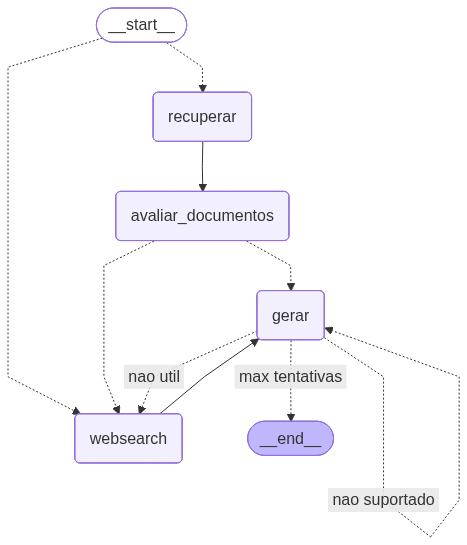

In [12]:
from langgraph.graph import StateGraph
from IPython.display import Image, display

workflow = StateGraph(GraphState)

# Adicionar nós
workflow.add_node("recuperar", recuperar)
workflow.add_node("websearch", pesquisa_web)
workflow.add_node("avaliar_documentos", avaliar_documentos)
workflow.add_node("gerar", gerar)

# Definir entrada condicional
workflow.set_conditional_entry_point(
    rotear_pergunta,
    {
        "websearch": "websearch",
        "recuperar": "recuperar",
    }
)

# Após websearch, ir direto para gerar
workflow.add_edge("websearch", "gerar")

# Após recuperar, avaliar documentos
workflow.add_edge("recuperar", "avaliar_documentos")

# Após avaliar documentos, decidir próximo passo
workflow.add_conditional_edges(
    "avaliar_documentos",
    decidir_gerar,
    {
        "websearch": "websearch",
        "gerar": "gerar",
    }
)

# Após gerar, verificar qualidade
workflow.add_conditional_edges(
    "gerar",
    avaliar_geracao_vs_documentos_e_pergunta,
    {
        "nao suportado": "gerar",
        "util": END,
        "nao util": "websearch",
        "max tentativas": END,
    }
)

# Compilar
app = workflow.compile()

# Mostrar diagrama
display(Image(app.get_graph().draw_mermaid_png()))

## 7. Testar o Sistema

In [13]:
import pandas as pd
from typing import List, Dict, Optional

In [14]:
def gerar_prompt_analise_itil(df: pd.DataFrame, idioma: str = 'pt', quantidade: int = 30) -> Optional[str]:
    """
    Filtra um DataFrame de tickets por idioma e monta um prompt em lote
    para análise do motor cognitivo baseada na ITIL 4.

    Args:
        df (pd.DataFrame): O DataFrame contendo os tickets consolidados.
        idioma (str): O idioma desejado para o filtro (ex: 'pt', 'en'). Padrão é 'pt'.
        quantidade (int): O número máximo de tickets no prompt. Padrão é 30.

    Returns:
        str: O texto final do prompt formatado, ou None se nenhum ticket for encontrado.
    """
    # 1. Filtra o DataFrame original para trazer apenas os tickets do idioma escolhido
    df_filtrado = df[df['idioma'] == idioma]

    # 2. Verifica se o filtro retornou resultados
    if df_filtrado.empty:
        print(f"AVISO: Nenhum ticket no idioma '{idioma}' foi encontrado no dataset.")
        return None

    # 3. Define a quantidade de tickets
    # Garantimos que não vamos pedir mais do que o total disponível
    limite = min(quantidade, len(df_filtrado))

    # 4. Início do Prompt (Cabeçalho único)
    prompt_texto = "Por favor, analise os seguintes tickets aplicando as diretrizes da ITIL 4 estabelecidas:\n"
    prompt_texto += "Para cada ticket, retorne qual Prática ITIL evitaria o incidente e resolveria o problema previamente, caso não seja identificado pratica\n"
    prompt_texto += "---"

    # 5. Laço de repetição para percorrer o grupo de tickets
    for i in range(limite):
        ticket_atual = df_filtrado.iloc[i]

        # Adiciona as informações do ticket atual ao texto do prompt
        prompt_texto += f"""

Ticket #{ticket_atual['Id']}:
Assunto: {ticket_atual['assunto']}
Descricao: {ticket_atual['descricao']}
Solução: {ticket_atual['resposta']}
----------------------------------"""

    prompt_final = prompt_texto + "\nE retorne qual Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente."

    print(f"Sucesso! Prompt montado para um lote de {limite} tickets.")

    return prompt_final



In [15]:
def gerar_prompt_excluindo_primeiros(df: pd.DataFrame, excluir: int = 1, idioma: str = 'pt', quantidade: int = 30) -> Optional[str]:
    """
    Gera o prompt a partir do df excluindo os primeiros `excluir` registros.
    """
    if excluir < 0:
        raise ValueError("excluir deve ser >= 0")
    df_slice = df.iloc[excluir:]
    if df_slice.empty:
        print(f"AVISO: Não há tickets após excluir os primeiros {excluir} registros.")
        return None
    # reutiliza a função já definida no notebook
    return gerar_prompt_analise_itil(df_slice, idioma=idioma, quantidade=quantidade)

In [16]:
# Carrega o arquivo df_tickets.csv para um DataFrame
caminho_csv = "amostra.csv"

if not os.path.exists(caminho_csv):
    raise FileNotFoundError(f"Arquivo não encontrado: {caminho_csv}")

df_tickets = pd.read_csv(caminho_csv)

print("✅ df_tickets carregado com sucesso!")
print(f"Linhas: {df_tickets.shape[0]} | Colunas: {df_tickets.shape[1]}")
display(df_tickets.head())

✅ df_tickets carregado com sucesso!
Linhas: 419 | Colunas: 10


,Id,assunto,fila,descricao,tipo,resposta,prioridade,todas_tags,idioma,descricao_length
0,3,Erro na Autocompletação de Código do IntelliJ ...,Technical Support,"Prezado Suporte ao Cliente <name>,\n\nEstou es...",Incident,"Prezado <name>,\n\nObrigado por entrar em cont...",high,"['Technical Support', 'Software Bug', 'Problem...",pt,740
1,25,Problemas intermitentes de exibição após atual...,Product Support,"Caro Suporte ao Cliente,\n\n Estou entrando em...",Problem,"Caro <name>,\n\n Obrigado por entrar em contat...",high,"['Technical Support', 'Product Support', 'Soft...",pt,975
2,42,Pedido de Assistência para Administração de Se...,Customer Service,"Prezado Suporte ao Cliente de Serviços de TI,\...",Request,"Prezado <name>,\n\nObrigado por entrar em cont...",medium,"['Technical Support', 'IT Support', 'Performan...",pt,1271
3,57,Urgente: Relato de Falha na Bateria do MacBook...,Returns and Exchanges,"Prezado Atendimento ao Cliente,<br><br>Recente...",Problem,"Prezado [Nome],<br><br>Lamento pelo inconvenie...",medium,"['Product Support', 'Hardware Failure', 'Retur...",pt,326
4,62,Assistência Necessária para Integração do Jira...,Technical Support,"Prezado Time de Suporte ao Cliente,\n\nEspero ...",Request,"Prezado <name>,\n\nObrigado por entrar em cont...",high,"['Technical Support', 'Product Support', 'Soft...",pt,1112


In [17]:
prompt = gerar_prompt_analise_itil(df_tickets, idioma='pt', quantidade=5)

Sucesso! Prompt montado para um lote de 5 tickets.


In [18]:
def chamar_agent_stream(
    prompt_lote: str,
    caminho_md: str = "resposta_agent_rag_adaptativo.md",
    exibir_conversa: bool = True,
) -> None:
    if not prompt_lote:
        print("Nao foi possivel gerar o prompt. Verifique os dados e tente novamente.")
        return

    import contextlib
    import io
    import os

    def _extrair_texto(valor):
        if isinstance(valor, str):
            return valor
        if isinstance(valor, list):
            partes = []
            for item in valor:
                if isinstance(item, dict):
                    if "text" in item:
                        partes.append(str(item["text"]))
                    elif "content" in item:
                        partes.append(str(item["content"]))
                    else:
                        partes.append(str(item))
                elif hasattr(item, "content"):
                    partes.append(str(item.content))
                else:
                    partes.append(str(item))
            return "\n".join(partes).strip()
        if isinstance(valor, dict):
            return _extrair_texto(valor.get("text") or valor.get("content") or valor)
        if hasattr(valor, "content"):
            return _extrair_texto(valor.content)
        return str(valor)

    def _formatar_estado(evento):
        linhas = []
        if not isinstance(evento, dict):
            return ""
        if "question" in evento:
            linhas.append(f"Pergunta: {evento['question']}")
        if "documents" in evento:
            linhas.append(f"Documentos recuperados: {len(evento['documents'])}")
        if "pesquisa_web" in evento:
            linhas.append(f"Pesquisa na web: {evento['pesquisa_web']}")
        if "generation" in evento and evento["generation"]:
            linhas.append(f"Resposta gerada:\n{_extrair_texto(evento['generation'])}")
        if "loop_step" in evento:
            linhas.append(f"Loop step: {evento['loop_step']}")
        return "\n".join(linhas).strip()

    print("Prompt gerado, chamando o agente...")

    entradas = {"question": prompt_lote, "max_retries": 2, "system": instrucao}
    buffer = io.StringIO()
    historico = []

    with contextlib.redirect_stdout(buffer):
        resultado_final = None
        for evento in app.stream(entradas, stream_mode="values"):
            resultado_final = evento
            trecho = _formatar_estado(evento)
            if trecho:
                historico.append(trecho)

    generation = resultado_final.get("generation") if isinstance(resultado_final, dict) else None
    final_text = _extrair_texto(generation)
    conversa_texto = "\n\n---\n\n".join(historico).strip()
    stdout_texto = buffer.getvalue().strip()

    filename = os.path.join(os.getcwd(), caminho_md)
    arquivo_existente = os.path.exists(filename) and os.path.getsize(filename) > 0

    with open(filename, "a", encoding="utf-8") as f:
        if arquivo_existente:
            f.write("\n\n")
        f.write("## Conversa do agente\n\n")
        if conversa_texto:
            f.write(conversa_texto)
        elif stdout_texto:
            f.write(stdout_texto)
        else:
            f.write("Nenhuma conversa foi registrada.")
        f.write("\n\n## Resposta final\n\n")
        f.write(final_text or "Nenhuma resposta final foi gerada.")
        f.write("\n\n---\n\n")

    if exibir_conversa:
        if conversa_texto:
            print(conversa_texto)
        elif stdout_texto:
            print(stdout_texto)
        print("\n## Resposta final\n")
        print(final_text or "Nenhuma resposta final foi gerada.")
    else:
        print(f"Resposta anexada em {filename}")


def processar_lotes(
    df: pd.DataFrame,
    num_lote: int = 5,
    tamanho_lote: int = 30,
    idioma: str = 'pt',
    caminho_md: str = 'resposta_agent_rag_adaptativo.md',
    exibir_conversa: bool = True,
) -> None:
    total_lotes = num_lote
    limite_total = min(len(df), total_lotes * tamanho_lote)

    if limite_total == 0:
        print("Nenhum ticket disponível para processamento em lotes.")
        return

    titulo = 'Respostas ITIL por Lote - RAG Adaptativo'
    with open(caminho_md, 'w', encoding='utf-8') as arquivo_md_saida:
        arquivo_md_saida.write(f'# {titulo}\n\n')

    for lote_numero in range(total_lotes):
        inicio = lote_numero * tamanho_lote
        fim = inicio + tamanho_lote

        if inicio >= limite_total:
            print(f'Lote {lote_numero + 1}: nenhum ticket restante.')
            break

        prompt_lote = gerar_prompt_excluindo_primeiros(
            df,
            excluir=inicio,
            idioma=idioma,
            quantidade=tamanho_lote,
        )
        if not prompt_lote:
            print(f'Lote {lote_numero + 1}: prompt vazio, pulando.')
            continue

        print(f'Processando lote {lote_numero + 1}/{total_lotes} com tickets {inicio + 1} a {min(fim, limite_total)}...')
        chamar_agent_stream(
            prompt_lote,
            caminho_md=caminho_md,
            exibir_conversa=exibir_conversa,
        )

In [19]:
processar_lotes(
    df_tickets,
    num_lote=5,
    tamanho_lote=30,
    idioma='pt',
    caminho_md='resposta_agent_rag_adaptativo.md',
    exibir_conversa=True,
)

Sucesso! Prompt montado para um lote de 30 tickets.
Processando lote 1/5 com tickets 1 a 30...
Prompt gerado, chamando o agente...
Pergunta: Por favor, analise os seguintes tickets aplicando as diretrizes da ITIL 4 estabelecidas:
Para cada ticket, retorne qual Prática ITIL evitaria o incidente e resolveria o problema previamente, caso não seja identificado pratica
---

Ticket #3:
Assunto: Erro na Autocompletação de Código do IntelliJ IDEA
Descricao: Prezado Suporte ao Cliente <name>,

Estou escrevendo para trazer à sua atenção um problema recorrente com o recurso de autocompletação de código no IntelliJ IDEA 2024.1. Este problema específico faz com que o aplicativo travar frequentemente durante o desenvolvimento, o que está prejudicando significativamente minha produtividade. Cada vez que tento usar o recurso de autocompletação de código, o software fica sem resposta, levando eventualmente a um travamento. Já tentei os passos comuns de solução de problemas, como reinstalação e aplicaçã

In [20]:
# prompt = gerar_prompt_excluindo_primeiros(df_tickets, excluir=15, idioma='pt', quantidade=15)
# chamar_agent_stream()

In [21]:
# # Teste 1: Pergunta sobre ITIL (deve usar vectorstore)
# print("=" * 50)
# print("TESTE 1: Pergunta sobre ITIL")
# print("=" * 50)
# inputs = {"question": "O que é ITIL e quais são seus benefícios?", "max_retries": 2}
# for event in app.stream(inputs, stream_mode="values"):
#     if "generation" in event:
#         print(f"\n✅ RESPOSTA FINAL:\n{event['generation']}\n")
#     if "documents" in event:
#         print(f"📄 Documentos recuperados: {len(event['documents'])}")


In [22]:
# # Teste 2: Pergunta sobre evento atual (deve usar websearch)
# print("=" * 50)
# print("TESTE 2: Pergunta sobre evento atual")
# print("=" * 50)
# inputs = {"question": "Quais foram as últimas notícias sobre IA generativa em Maio de 2025?", "max_retries": 2}
# for event in app.stream(inputs, stream_mode="values"):
#     if "generation" in event:
#         print(f"\n✅ RESPOSTA FINAL:\n{event['generation']}\n")


In [23]:
# # Teste 3: Pergunta que pode exigir fallback (documentos irrelevantes)
# print("=" * 50)
# print("TESTE 3: Pergunta que pode exigir busca na web como fallback")
# print("=" * 50)
# inputs = {"question": "Como implementar ITIL em uma empresa de software?", "max_retries": 2}
# for event in app.stream(inputs, stream_mode="values"):
#     if "generation" in event:
#         print(f"\n✅ RESPOSTA FINAL:\n{event['generation']}\n")
